# BİL458 Bilgisayarlı Görme — Dönem Projesi (BIL458 Computer Vision — Term Project)

**Project title:** CancerAI: A Comparative Study of Deep Learning Strategies for Multi-Modal Medical Image Classification
**Team:** Farah Alhasan (21120205709) — individual project
**Instructor:** Assoc. Prof. Murat GEZER

This notebook accompanies the project report and follows the same section order (0 Environment → 10 Demo). It studies four separate classification tasks: brain MRI, breast histopathology (BreakHis), skin lesions (DermaMNIST / HAM10000) and lung CT (IQ-OTH/NCCD). The labels are tumour and lesion categories; the system is a comparison of training strategies and is not intended for clinical use.

**Reproducibility.** The results of the 48 training runs (4 datasets × 4 configurations × 3 seeds) are loaded from their stored metric files, and the notebook runs end to end with *Kernel → Restart & Run All*. Section 5 describes how to retrain.

## 0. Environment and reproducibility

**Research question.** Does the CNN training strategy (from scratch, frozen ImageNet backbone, full fine-tuning) and training-time augmentation change test macro-F1, and is the change the same on all four modalities?

- **H1.** Fine-tuned ResNet18 beats a custom CNN trained from scratch (baseline) and a frozen ResNet18.
- **H2.** Training augmentation improves the fine-tuned model, especially where classes are imbalanced.
- **H3.** The size of the gain depends on the modality.
- **H4.** Accuracy hides weak minority classes; macro-F1 and per-class recall reveal them.

Training seeds: **42, 123, 2026**. The data split is fixed once (split seed 42) and does not change with the training seed. Every score is mean ± sample standard deviation over the three seeds.

In [1]:
import os, sys, subprocess, platform, random, json, time
from pathlib import Path

def find_project(start):
    for candidate in (start, start.parent, Path("/content/CancerAI")):
        if (candidate / "cancerai" / "__init__.py").exists():
            return candidate.resolve()
    return None

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

ROOT = find_project(Path.cwd().resolve())
if ROOT is None and IN_COLAB:  # Colab: fetch the code (the images are not redistributed)
    ROOT = Path("/content/CancerAI")
    if not (ROOT / "cancerai" / "__init__.py").exists():
        subprocess.check_call(["git", "clone", "--depth", "1", "https://github.com/FarahBebs/CancerAI.git", str(ROOT)])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "medmnist", "pillow-heif"])
if ROOT is None:
    raise FileNotFoundError("Project folder not found. Open the notebook from the CancerAI project directory.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, Markdown, display
from cancerai.training import get_device, seed_everything
from cancerai.datasets import resolve_data_root

def show(fig=None):
    # Display a figure explicitly (a project module selects the non-interactive Agg backend).
    fig = fig or plt.gcf()
    display(fig)
    plt.close(fig)

SEED = 42
SEEDS = (42, 123, 2026)
seed_everything(SEED)  # random, numpy, torch (+ cudnn deterministic flags)

def collection_present() -> bool:
    # True when the image collections are available on this machine.
    root = resolve_data_root()
    if not root.exists():
        return False
    suffixes = {".jpg", ".jpeg", ".png", ".npz", ".tif", ".tiff"}
    return any(p.suffix.lower() in suffixes for p in root.rglob("*") if p.is_file())

DATA_READY = collection_present()
print("python ", platform.python_version())
print("torch  ", torch.__version__)
print("device ", get_device())
print("project", ROOT)
print("images available:", DATA_READY)

python  3.13.2
torch   2.15.0
device  mps
project /Users/farahalhasan/Desktop/Projects/computer vision
images available: True


## 1. Dataset

| Dataset | Source / licence | Classes | Split level |
|---|---|---|---|
| Brain Tumor MRI | Kaggle (Nickparvar), CC BY 4.0 | glioma, meningioma, pituitary, no tumour | image (official Testing folder held out) |
| BreakHis | Spanhol et al., UFPR research release | 8 subtypes (4 benign, 4 malignant) | **patient** (54 / 14 / 14 patients) |
| DermaMNIST (HAM10000) | MedMNIST v2, CC BY-NC 4.0 | 7 lesion types | official MedMNIST split |
| IQ-OTH/NCCD lung CT | public teaching set | normal, benign, malignant | image (stratified) |

**The train / validation / test split is done once and written to `results/splits/` (no data leakage).** Every subsequent run reloads that file. Training is refused if the same image path, or the same BreakHis patient, appears in two splits. Brain MRI and lung CT filenames contain no patient identifier, so those two results are not claimed to be patient-level. The split audit below is read from `results/audit.json`.

dataset  grouping           patient-level   train    val   test
brain    image                      False    4855    857   1311
breast   patient                     True    4973   1399   1537
skin     official_medmnist          False    7007   1003   2005
lung     image                      False     767    165    165


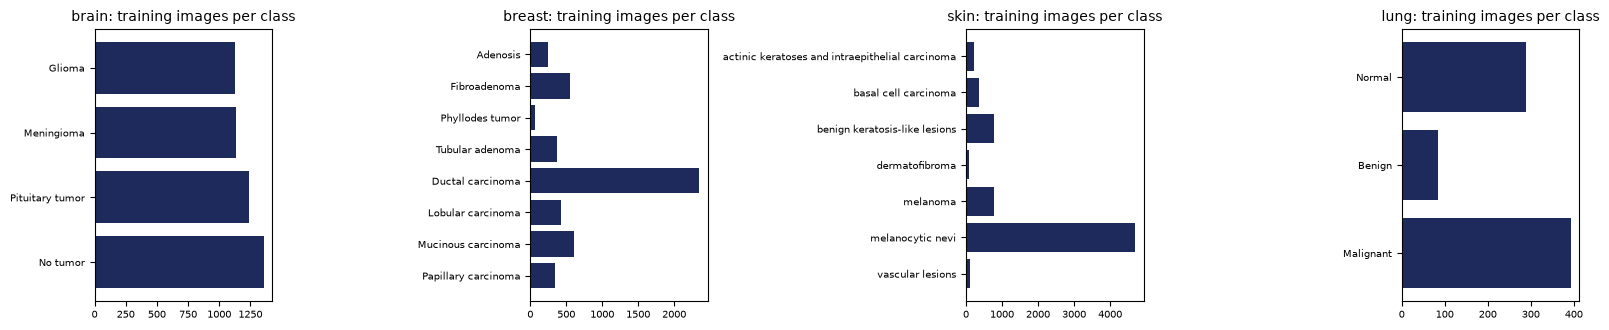

In [2]:
audit = json.loads((ROOT / "results" / "audit.json").read_text())
rows = []
for name, entry in audit["datasets"].items():
    counts = {split: sum(c.values()) for split, c in entry["counts"].items()}
    rows.append((name, entry.get("grouping"), entry["patient_independent"], counts["train"], counts["val"], counts["test"]))
print(f"{'dataset':8} {'grouping':18} {'patient-level':>13} {'train':>7} {'val':>6} {'test':>6}")
for r in rows:
    print(f"{r[0]:8} {str(r[1]):18} {str(r[2]):>13} {r[3]:7d} {r[4]:6d} {r[5]:6d}")

# Class distribution of the training split: shows the imbalance that motivates class weights and macro-F1.
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (name, entry) in zip(axes, audit["datasets"].items()):
    train = entry["counts"]["train"]
    ax.barh(list(train.keys()), list(train.values()), color="#1F2A5C")
    ax.set_title(f"{name}: training images per class", fontsize=10)
    ax.tick_params(labelsize=7)
    ax.invert_yaxis()
plt.tight_layout(); show()

In [3]:
# Leakage check on the saved split files (needs only results/splits/, not the images).
from cancerai.datasets import load_manifest, assert_disjoint
for name in ("brain", "breast", "skin", "lung"):
    manifest = load_manifest(name)
    if manifest is None:
        print(f"{name}: split file not found (generate it with `python -m cancerai.datasets`).")
        continue
    assert_disjoint(manifest)  # raises if a path or patient appears in two splits
    print(f"{name}: train/val/test are disjoint ✓")

brain: train/val/test are disjoint ✓
breast: train/val/test are disjoint ✓
skin: train/val/test are disjoint ✓
lung: train/val/test are disjoint ✓


## 2. Preprocessing and data augmentation

Every model receives a 224×224 RGB image normalised with the ImageNet mean (0.485, 0.456, 0.406) and std (0.229, 0.224, 0.225). Augmentation is **training-only** and modality-specific:

- **Breast histopathology:** horizontal + vertical flip, rotation ±20°, mild brightness/contrast. Hue unchanged (stain colour is informative).
- **Skin lesions:** horizontal flip, rotation ±15°, mild brightness/contrast/saturation. Hue unchanged.
- **Brain MRI:** rotation ±10°, no flip (left/right is anatomical).
- **Lung CT:** rotation ±8°, no flip, no colour change.

Validation and test images are only resized and normalised.

brain  train: ['Resize', 'RandomResizedCrop', 'RandomRotation', 'ToTensor', 'Normalize']
breast train: ['Resize', 'RandomResizedCrop', 'RandomHorizontalFlip', 'RandomVerticalFlip', 'RandomRotation', 'ColorJitter', 'ToTensor', 'Normalize']
skin   train: ['Resize', 'RandomResizedCrop', 'RandomHorizontalFlip', 'RandomRotation', 'ColorJitter', 'ToTensor', 'Normalize']
lung   train: ['Resize', 'RandomResizedCrop', 'RandomRotation', 'ToTensor', 'Normalize']
eval   (all): ['Resize', 'ToTensor', 'Normalize']


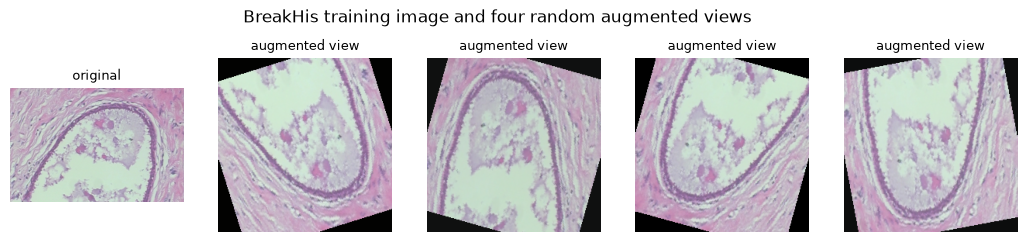

In [4]:
from cancerai.datasets import build_transform, prepare

def steps(dataset, train, augment):
    return [type(s).__name__ for s in build_transform(dataset, train=train, augment=augment).transforms]

for dataset in ("brain", "breast", "skin", "lung"):
    print(f"{dataset:6} train:", steps(dataset, True, True))
print("eval   (all):", steps("brain", False, False))

if DATA_READY:
    try:
        bundle = prepare("breast", augment=True)
        tf = build_transform("breast", train=True, augment=True)
        raw = bundle.train_ds.raw(0)
        fig, axes = plt.subplots(1, 5, figsize=(13, 2.8))
        axes[0].imshow(raw); axes[0].set_title("original", fontsize=9)
        mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
        for ax in axes[1:]:
            x = tf(raw).permute(1, 2, 0).numpy() * std + mean
            ax.imshow(np.clip(x, 0, 1)); ax.set_title("augmented view", fontsize=9)
        for ax in axes: ax.axis("off")
        plt.suptitle("BreakHis training image and four random augmented views"); show()
    except (FileNotFoundError, RuntimeError, OSError) as exc:
        print("Augmentation preview skipped:", exc)
else:
    print("Image data not available; augmentation preview skipped.")

## 3. Baseline

The baseline is a **four-block CNN trained from scratch** (no ImageNet weights): three blocks of 3×3 convolution → ReLU → 2×2 max-pool (32, 64, 128 channels), a fourth 3×3 convolution to 256 channels, global average pooling, dropout 0.3 and a linear layer.

A convolution reads a local patch, $Y(i,j)=\sum_{u=0}^{k-1}\sum_{v=0}^{k-1} X(i+u,j+v)\,K(u,v)$, followed by $\mathrm{ReLU}(x)=\max(0,x)$. One layer costs $O(H\,W\,k^2\,C_{in}\,C_{out})$ multiply-accumulates (MACs). The cell below counts the parameters and MACs of the three models and times one forward pass (complexity analysis, report Section 2.4).

In [5]:
from cancerai.models import build_model, count_params

def count_macs(model, size=224):
    # Multiply-accumulate operations for one 3x224x224 image (convolutions + linear layers).
    macs = []
    def conv_hook(m, i, o):
        macs.append(o.numel() * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1])
    def lin_hook(m, i, o):
        macs.append(m.in_features * m.out_features)
    hooks = [m.register_forward_hook(conv_hook) for m in model.modules() if isinstance(m, torch.nn.Conv2d)]
    hooks += [m.register_forward_hook(lin_hook) for m in model.modules() if isinstance(m, torch.nn.Linear)]
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, size, size))
    for h in hooks: h.remove()
    return sum(macs)

def cpu_ms(model, repeats=20):
    x = torch.zeros(1, 3, 224, 224); model.eval()
    with torch.no_grad():
        for _ in range(3): model(x)
        t = time.perf_counter()
        for _ in range(repeats): model(x)
    return (time.perf_counter() - t) / repeats * 1000

print(f"{'model (4 classes)':24} {'total params':>13} {'trainable':>11} {'GMACs':>7} {'CPU ms':>7}")
for label, name, freeze in (("custom CNN (baseline)", "custom_cnn", False),
                            ("frozen ResNet18", "resnet18", True),
                            ("fine-tuned ResNet18", "resnet18", False)):
    model = build_model(name, n_classes=4, freeze_backbone=freeze, pretrained=False)
    total, trainable = count_params(model)
    print(f"{label:24} {total:13,d} {trainable:11,d} {count_macs(model)/1e9:7.3f} {cpu_ms(model):7.1f}")

model (4 classes)         total params   trainable   GMACs  CPU ms


custom CNN (baseline)          389,444     389,444   0.737     6.9


frozen ResNet18             11,178,564       2,052   1.814    11.2


fine-tuned ResNet18         11,178,564  11,178,564   1.814     9.7


## 4. Proposed method

The comparison model is **ImageNet-pretrained ResNet18** [He et al., 2016]; its 1000-way layer is replaced by dropout 0.3 + a linear layer with $C$ outputs. Three settings: **frozen** (backbone fixed, only the head learns), **fine-tuned with augmentation**, **fine-tuned without augmentation** (the ablation).

**Loss — Eq. (1)–(2) of the report.** Class-weighted cross-entropy over a batch of $B$ images, with logits $z$:

$$\mathcal{L} = -\frac{1}{B}\sum_{b=1}^{B} w_{y_b}\,\log \operatorname{softmax}(z_b)_{y_b}, \qquad w_c = \frac{N}{C\,n_c}\ \ (\text{rescaled to mean } 1)$$

where $N$ is the number of training images, $n_c$ the number in class $c$. Rare classes get larger weights.

**Metric — Eq. (3).** Macro-F1 gives every class the same weight, so a large class cannot hide a weak one:

$$F1_{macro}=\frac{1}{C}\sum_{c=1}^{C}\frac{2P_cR_c}{P_c+R_c}$$

The implementation used in training (`cancerai/training.py`) is shown below; Section 9 verifies it against the formula.

In [6]:
import inspect
from cancerai.training import weighted_cross_entropy
from cancerai.datasets import class_weights
print(inspect.getsource(weighted_cross_entropy))

# Class weights on the real BreakHis training counts: phyllodes (rare) gets the largest weight.
breast_train = audit["datasets"]["breast"]["counts"]["train"]
labels = sum(([i] * n for i, n in enumerate(breast_train.values())), [])
for cls, w in zip(breast_train, class_weights(labels, len(breast_train)).tolist()):
    print(f"  {cls:22} n={breast_train[cls]:5d}  w={w:.2f}")

def weighted_cross_entropy(logits, target, weight):
    """Batch mean of L = -sum_c w_c y_c log yhat_c.

    y is one-hot, so only the true class remains. This is the weighted
    cross-entropy written in the report. It is not PyTorch's default
    `CrossEntropyLoss(weight=...)`, which also divides by the sum of the
    weights in the batch.
    """
    log_probs = torch.log_softmax(logits, dim=1)
    picked = log_probs.gather(1, target.view(-1, 1)).squeeze(1)
    return -(weight[target] * picked).mean()

  Adenosis               n=  251  w=0.98
  Fibroadenoma           n=  557  w=0.44
  Phyllodes tumor        n=   60  w=4.11
  Tubular adenoma        n=  372  w=0.66
  Ductal carcinoma       n= 2350  w=0.10
  Lobular carcinoma      n=  429  w=0.57
  Mucinous carcinoma     n=  611  w=0.40
  Papillary carcinoma    n=  343  w=0.72


## 5. Training

All configurations share `cancerai.training.train_model`: **AdamW** (weight decay $10^{-4}$), cosine learning-rate decay to $10^{-6}$, batch 32, input 224. The kept checkpoint is the epoch with the best **validation macro-F1**; early stopping after 3 epochs without a gain of 0.001. The test set is scored **once**, after the best epoch is restored.

| Configuration | Trained weights | Augmentation | Epoch cap | Learning rate |
|---|---|---|---:|---:|
| `custom_cnn` (baseline) | all (~0.39M) | on | 10 | $10^{-3}$ |
| `frozen_resnet18` | head only | on | 8 | $10^{-3}$ |
| `finetune_aug` (proposed) | all (11.18M) | on | 8 | $10^{-4}$ |
| `finetune_no_aug` (ablation) | all (11.18M) | off | 8 | $10^{-4}$ |

4 configurations × 3 seeds × 4 datasets = **48 runs**, trained on Apple Silicon (MPS) with PyTorch. Setting `RUN_FULL_STUDY = True` below retrains every configuration whose metric file is missing.

Stored results loaded.
training runs: 48


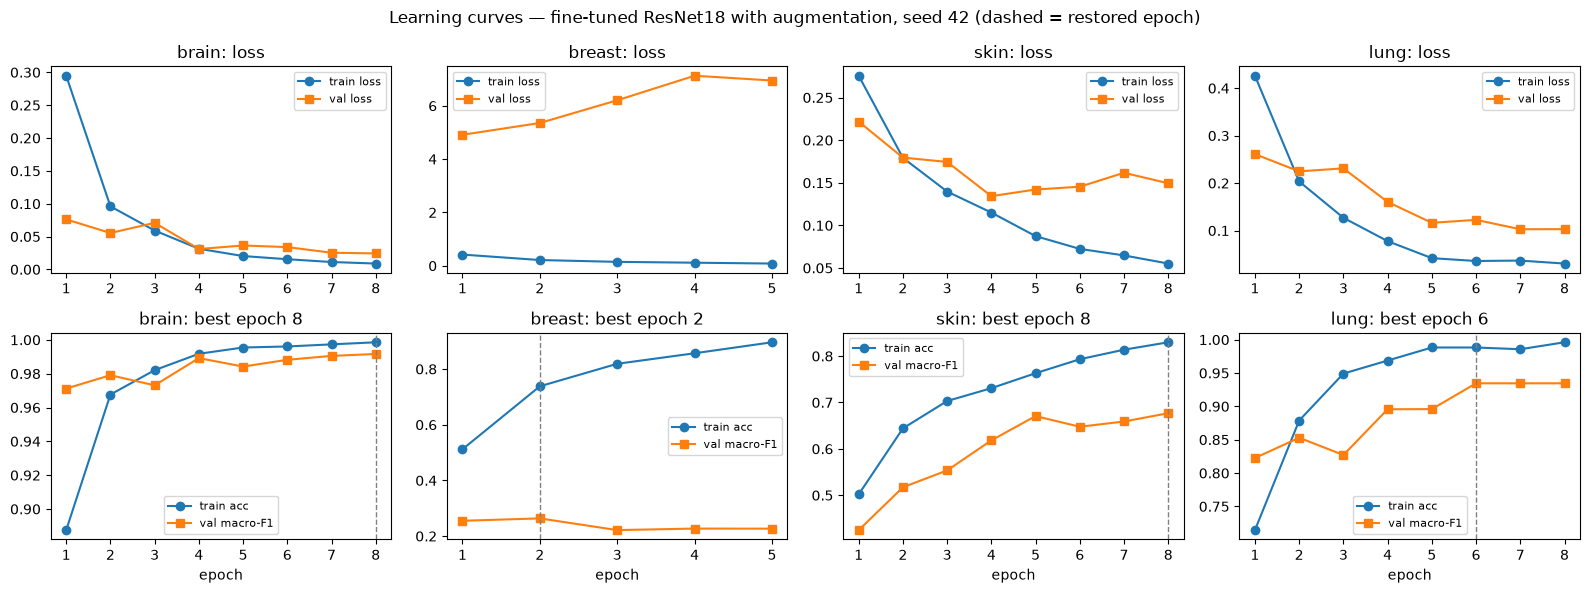

In [7]:
RUN_FULL_STUDY = False  # True: retrain configurations without a stored metric file (several hours)

if RUN_FULL_STUDY:
    from experiments.run_experiments import main
    main([])
else:
    print("Stored results loaded.")

from experiments.summarize import load_runs
runs = load_runs()
print("training runs:", len(runs))

# Learning curves of the proposed model (seed 42) for the four datasets.
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for col, ds in enumerate(("brain", "breast", "skin", "lung")):
    r = next(x for x in runs if x["dataset"] == ds and x["config"] == "finetune_aug" and x["seed"] == 42)
    h = r["history"]
    axes[0, col].plot(h["epoch"], h["train_loss"], "o-", label="train loss")
    axes[0, col].plot(h["epoch"], h["val_loss"], "s-", label="val loss")
    axes[0, col].set_title(f"{ds}: loss"); axes[0, col].legend(fontsize=8)
    axes[1, col].plot(h["epoch"], h["train_acc"], "o-", label="train acc")
    axes[1, col].plot(h["epoch"], h["val_macro_f1"], "s-", label="val macro-F1")
    axes[1, col].axvline(r["best_epoch"], ls="--", c="gray", lw=1)
    axes[1, col].set_title(f"{ds}: best epoch {r['best_epoch']}"); axes[1, col].legend(fontsize=8)
    axes[1, col].set_xlabel("epoch")
plt.suptitle("Learning curves — fine-tuned ResNet18 with augmentation, seed 42 (dashed = restored epoch)")
plt.tight_layout(); show()

## 6. Evaluation (≥ 3 seeds, mean ± std)

Primary metric: **test macro-F1**. Secondary: accuracy, macro precision/recall, ROC-AUC (one-vs-rest, macro), training time and single-image inference time. Per-seed values are listed alongside the mean ± std. A Welch *t*-test across the three seeds compares fine-tuning with each alternative; with three seeds per group the test has limited statistical power.

In [8]:
from scipy import stats
DATASETS = ("brain", "breast", "skin", "lung")
CONFIGS = ("custom_cnn", "frozen_resnet18", "finetune_aug", "finetune_no_aug")

def values(ds, cfg, key="f1_macro"):
    return np.array([r["test"][key] for r in runs if r["dataset"] == ds and r["config"] == cfg])

def ms(v):
    return f"{v.mean():.3f} ± {v.std(ddof=1):.3f}"

print("Test macro-F1 per seed (42, 123, 2026) and mean ± sample std\n")
for ds in DATASETS:
    print(ds)
    for cfg in CONFIGS:
        seeds = sorted((r["seed"], r["test"]["f1_macro"]) for r in runs if r["dataset"] == ds and r["config"] == cfg)
        print(f"   {cfg:16}", "  ".join(f"{s}:{v:.3f}" for s, v in seeds), "  →", ms(values(ds, cfg)))

print("\nSummary table (Table 4 of the report)")
print(f"{'dataset':8} {'custom CNN':>16} {'frozen ResNet18':>16} {'fine-tuned':>16} {'acc (fine-tuned)':>17} {'infer ms':>9}")
for ds in DATASETS:
    infer = np.mean([r["inference_ms"] for r in runs if r["dataset"] == ds and r["config"] == "finetune_aug"])
    print(f"{ds:8} {ms(values(ds,'custom_cnn')):>16} {ms(values(ds,'frozen_resnet18')):>16} "
          f"{ms(values(ds,'finetune_aug')):>16} {ms(values(ds,'finetune_aug','accuracy')):>17} {infer:9.1f}")

print("\nWelch t-test, fine-tuned vs. alternative (test macro-F1, n = 3 per group)")
for ds in DATASETS:
    ft = values(ds, "finetune_aug")
    for other in ("custom_cnn", "frozen_resnet18"):
        t, p = stats.ttest_ind(ft, values(ds, other), equal_var=False)
        print(f"   {ds:6} vs {other:16} Δ = {ft.mean()-values(ds, other).mean():+.3f}   p = {p:.4f}")

Test macro-F1 per seed (42, 123, 2026) and mean ± sample std

brain
   custom_cnn       42:0.711  123:0.731  2026:0.729   → 0.724 ± 0.011
   frozen_resnet18  42:0.834  123:0.839  2026:0.836   → 0.837 ± 0.002
   finetune_aug     42:0.991  123:0.985  2026:0.991   → 0.989 ± 0.004
   finetune_no_aug  42:0.988  123:0.978  2026:0.989   → 0.985 ± 0.006
breast
   custom_cnn       42:0.288  123:0.274  2026:0.255   → 0.272 ± 0.016
   frozen_resnet18  42:0.351  123:0.324  2026:0.372   → 0.349 ± 0.024
   finetune_aug     42:0.536  123:0.508  2026:0.475   → 0.506 ± 0.031
   finetune_no_aug  42:0.437  123:0.485  2026:0.463   → 0.462 ± 0.024
skin
   custom_cnn       42:0.380  123:0.362  2026:0.370   → 0.371 ± 0.009
   frozen_resnet18  42:0.353  123:0.338  2026:0.340   → 0.344 ± 0.008
   finetune_aug     42:0.709  123:0.735  2026:0.712   → 0.719 ± 0.014
   finetune_no_aug  42:0.738  123:0.780  2026:0.769   → 0.762 ± 0.022
lung
   custom_cnn       42:0.317  123:0.398  2026:0.384   → 0.366 ± 0.044
   fr

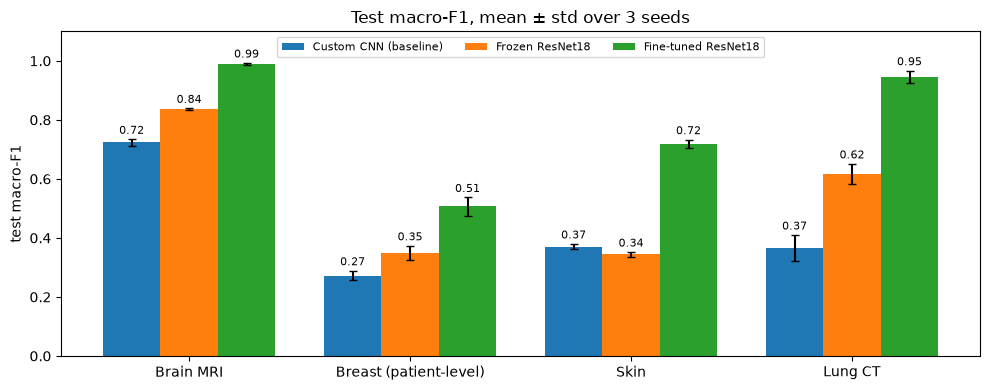

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
labels = {"custom_cnn": "Custom CNN (baseline)", "frozen_resnet18": "Frozen ResNet18", "finetune_aug": "Fine-tuned ResNet18"}
xs = np.arange(len(DATASETS)); width = 0.26
for k, cfg in enumerate(labels):
    means = [values(ds, cfg).mean() for ds in DATASETS]
    stds = [values(ds, cfg).std(ddof=1) for ds in DATASETS]
    bars = ax.bar(xs + (k - 1) * width, means, width, yerr=stds, capsize=3, label=labels[cfg])
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(xs, ["Brain MRI", "Breast (patient-level)", "Skin", "Lung CT"])
ax.set_ylabel("test macro-F1"); ax.set_ylim(0, 1.1); ax.legend(fontsize=8, ncol=3, loc="upper center")
ax.set_title("Test macro-F1, mean ± std over 3 seeds"); plt.tight_layout(); show()

## 7. Ablation study

The ablation switches **training augmentation off** for the fine-tuned ResNet18. Everything else is identical: same split, same learning rate, same seeds, same early stopping. A second, implicit ablation is *frozen vs. fine-tuned* (Section 6): it removes backbone adaptation while keeping the same network.

dataset          with aug      without aug   Δ (with − without)  p (Welch)
brain       0.989 ± 0.004    0.985 ± 0.006               +0.004      0.379
breast      0.506 ± 0.031    0.462 ± 0.024               +0.045      0.122
skin        0.719 ± 0.014    0.762 ± 0.022               -0.044      0.053
lung        0.946 ± 0.021    0.992 ± 0.007               -0.047      0.051


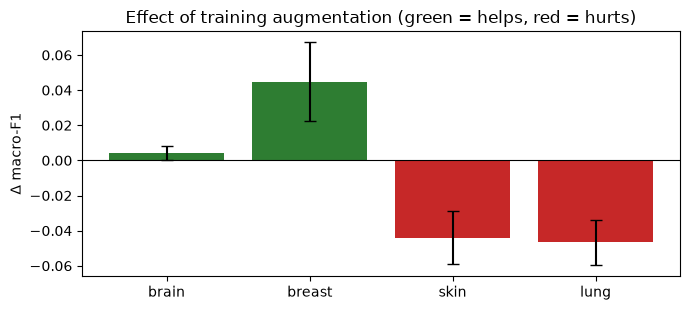

In [10]:
print(f"{'dataset':8} {'with aug':>16} {'without aug':>16} {'Δ (with − without)':>20} {'p (Welch)':>10}")
deltas, errs = [], []
for ds in DATASETS:
    a, b = values(ds, "finetune_aug"), values(ds, "finetune_no_aug")
    _, p = stats.ttest_ind(a, b, equal_var=False)
    deltas.append(a.mean() - b.mean()); errs.append(np.sqrt(a.var(ddof=1) / 3 + b.var(ddof=1) / 3))
    print(f"{ds:8} {ms(a):>16} {ms(b):>16} {deltas[-1]:+20.3f} {p:10.3f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
colors = ["#2E7D32" if d > 0 else "#C62828" for d in deltas]
ax.bar(DATASETS, deltas, yerr=errs, capsize=4, color=colors)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Δ macro-F1"); ax.set_title("Effect of training augmentation (green = helps, red = hurts)")
plt.tight_layout(); show()

## 8. Failure analysis

Aggregate scores conceal where the model fails. This section reports (a) per-class F1 of the proposed model, (b) confusion matrices and (c) the **five most confident errors** per dataset with Grad-CAM. Observed causes:

- **BreakHis — phyllodes tumour F1 ≈ 0.01.** About 143 of 235 test slides are called *fibroadenoma*: both are benign fibro-epithelial tumours that look alike at slide level, and only 60 phyllodes slides are in training. Grad-CAM sits on tissue, not on the border, so this is a look-alike confusion, not an artefact. Ductal ↔ lobular carcinoma is the second largest exchange.
- **DermaMNIST — melanoma precision 0.48.** About 140 nevi are called melanoma. The class weights buy melanoma recall (0.69) at the cost of precision. Nevi are 1,341 of 2,005 test images, so accuracy (0.787) is higher than macro-F1 (0.719): **H4**.
- **Brain MRI / lung CT.** Scores near 0.95–0.99, but filenames carry no patient id; neighbouring slices of one scan can be in train and test, so these are upper bounds. Benign lung has only 18 test slices.

In [11]:
print("Per-class test F1 of fine-tuned ResNet18 + augmentation (mean ± std over 3 seeds)\n")
for ds in DATASETS:
    rs = [r for r in runs if r["dataset"] == ds and r["config"] == "finetune_aug"]
    classes = list(rs[0]["test"]["per_class"].keys())
    print(ds)
    scored = []
    for c in classes:
        f1 = np.array([r["test"]["per_class"][c]["f1"] for r in rs])
        rec = np.mean([r["test"]["per_class"][c]["recall"] for r in rs])
        prec = np.mean([r["test"]["per_class"][c]["precision"] for r in rs])
        scored.append((f1.mean(), c, f1.std(ddof=1), prec, rec, rs[0]["test"]["per_class"][c]["support"]))
    for f1m, c, f1s, prec, rec, n in sorted(scored):
        flag = "  ← weakest" if f1m == min(s[0] for s in scored) else ""
        print(f"   {c:28} n={n:5d}  P={prec:.3f}  R={rec:.3f}  F1={f1m:.3f} ± {f1s:.3f}{flag}")

Per-class test F1 of fine-tuned ResNet18 + augmentation (mean ± std over 3 seeds)

brain
   Meningioma                   n=  306  P=0.979  R=0.979  F1=0.979 ± 0.005  ← weakest
   Glioma                       n=  300  P=0.991  R=0.981  F1=0.986 ± 0.007
   Pituitary tumor              n=  300  P=0.993  R=0.994  F1=0.994 ± 0.003
   No tumor                     n=  405  P=0.993  R=1.000  F1=0.997 ± 0.001
breast
   Phyllodes tumor              n=  235  P=0.021  R=0.004  F1=0.007 ± 0.012  ← weakest
   Mucinous carcinoma           n=   62  P=0.270  R=0.527  F1=0.357 ± 0.030
   Papillary carcinoma          n=   90  P=0.284  R=0.530  F1=0.369 ± 0.032
   Lobular carcinoma            n=  123  P=0.395  R=0.515  F1=0.445 ± 0.066
   Fibroadenoma                 n=  247  P=0.492  R=0.706  F1=0.579 ± 0.040
   Tubular adenoma              n=   65  P=0.750  R=0.692  F1=0.710 ± 0.103
   Ductal carcinoma             n=  583  P=0.817  R=0.718  F1=0.764 ± 0.008
   Adenosis                     n=  132  P=0.8

most confident mistakes (index): [1, 3]


**BreakHis** — confusion matrix and the 5 most confident test mistakes with Grad-CAM (fine-tuned ResNet18 + aug., seed 42).

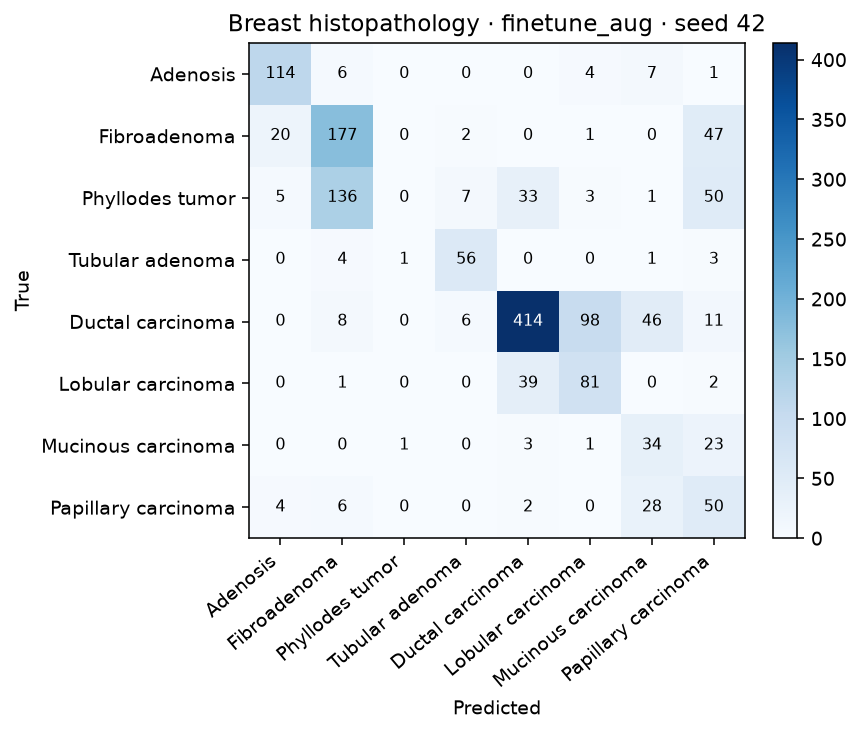

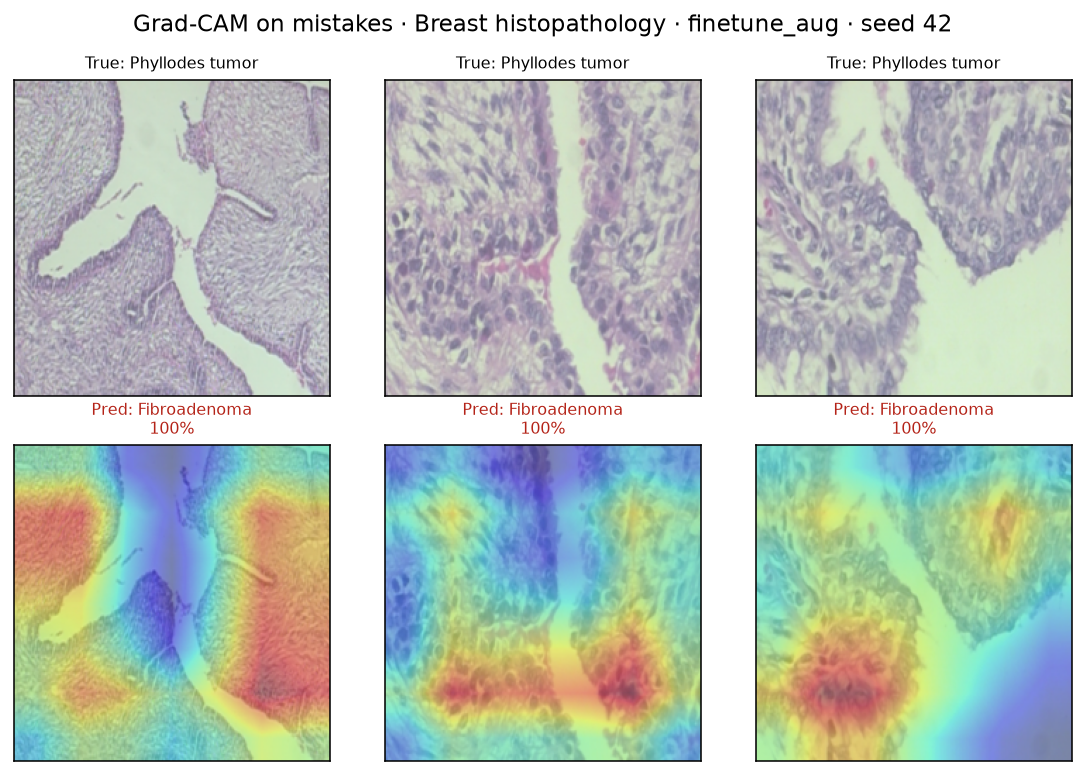

**DermaMNIST** — confusion matrix and the 5 most confident test mistakes with Grad-CAM (fine-tuned ResNet18 + aug., seed 42).

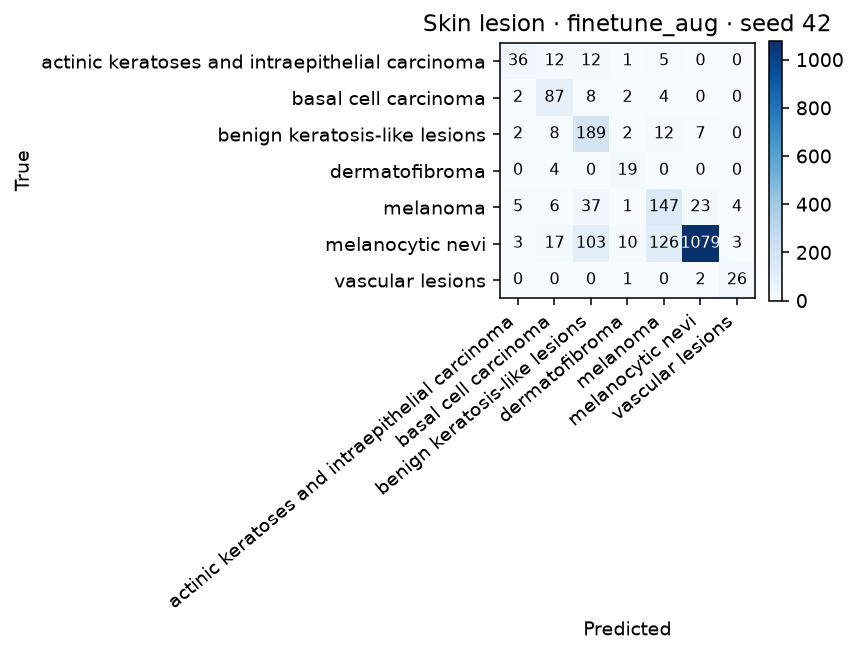

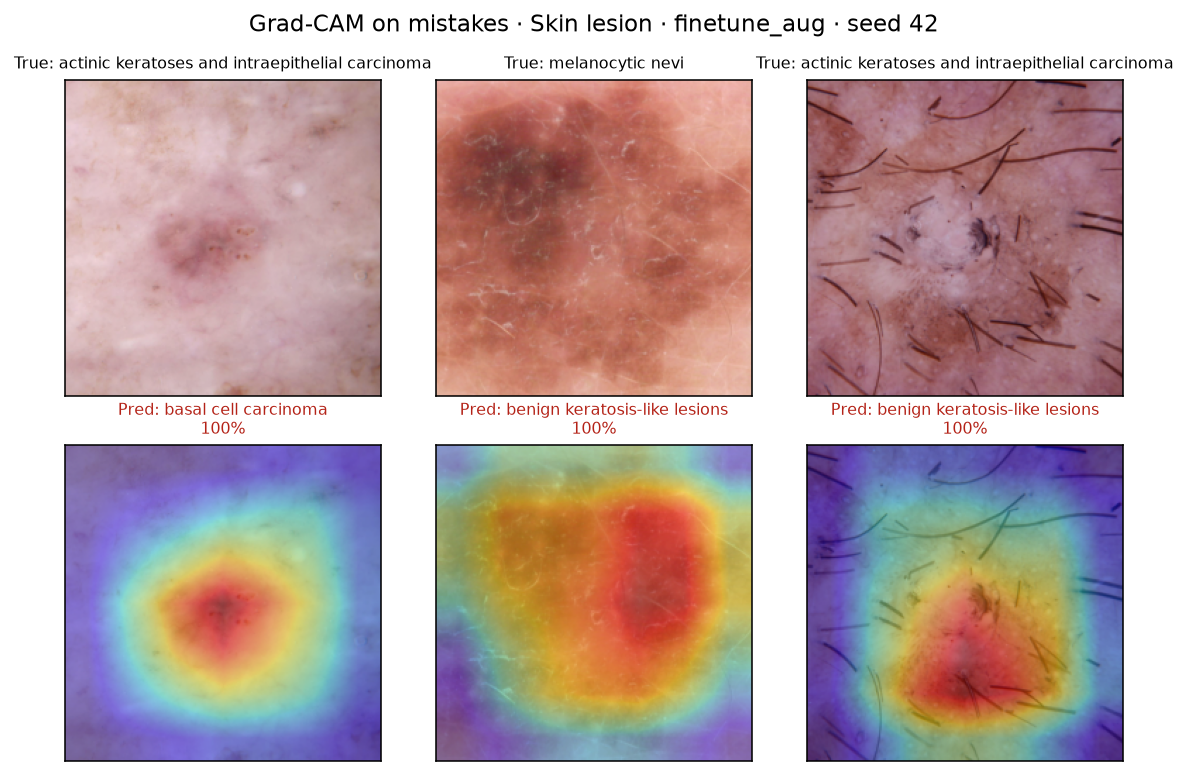

**Lung CT** — confusion matrix and the 5 most confident test mistakes with Grad-CAM (fine-tuned ResNet18 + aug., seed 42).

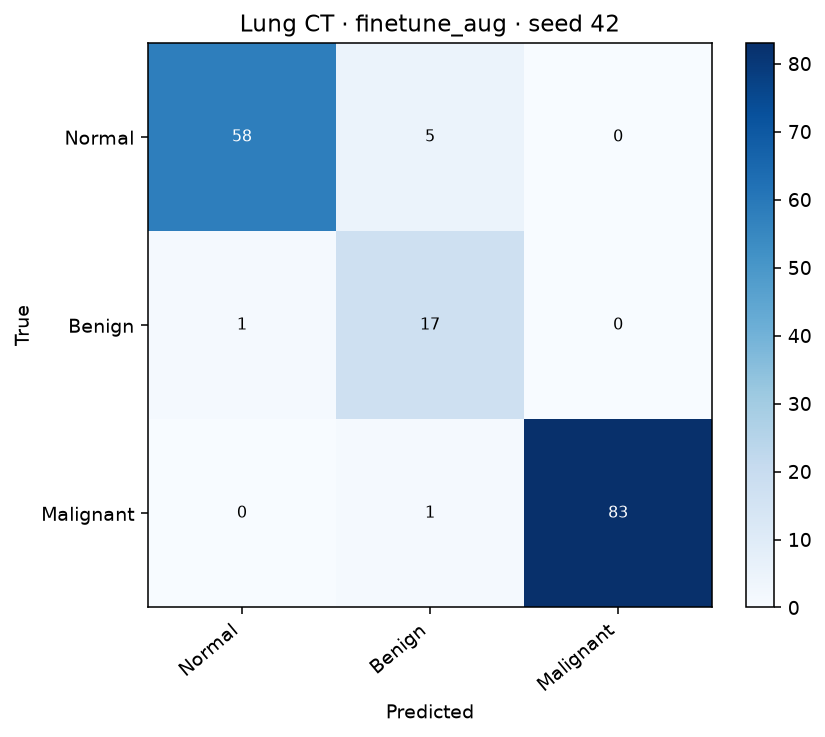

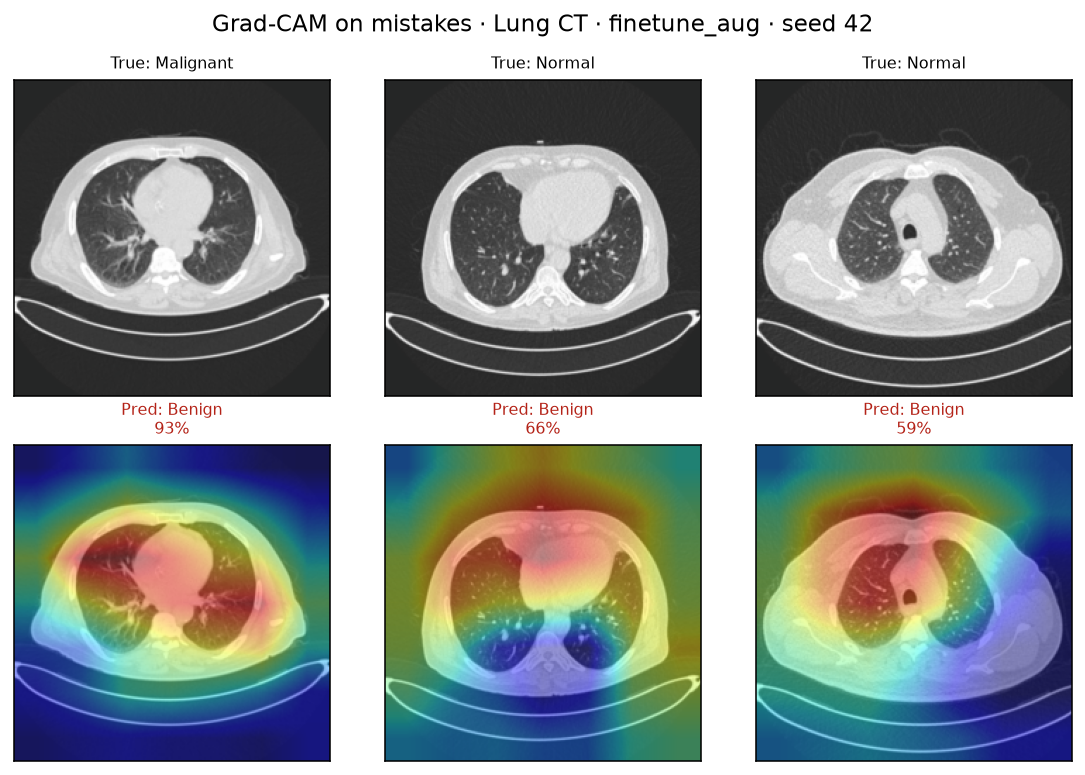

**Brain MRI** — confusion matrix and the 5 most confident test mistakes with Grad-CAM (fine-tuned ResNet18 + aug., seed 42).

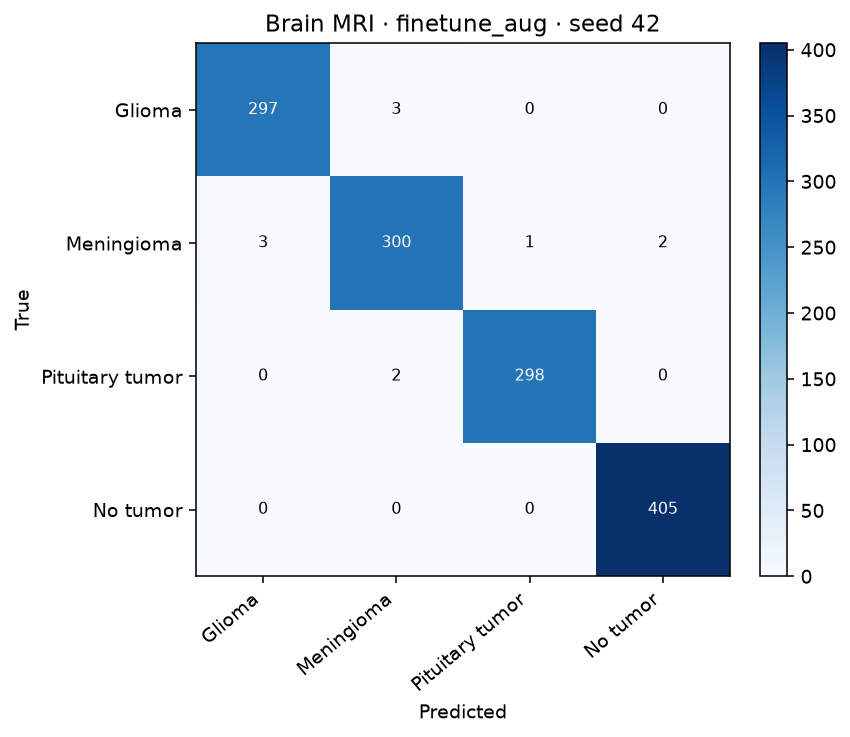

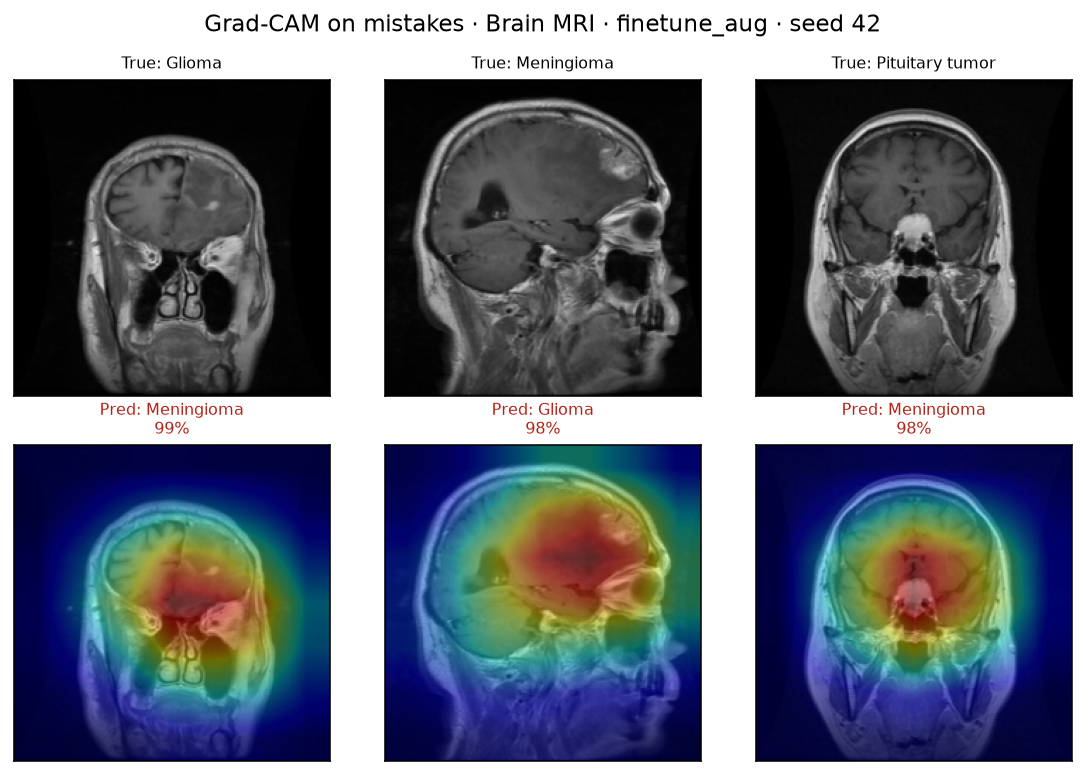

In [12]:
from cancerai.metrics import worst_mistakes
# The failure picker returns the k most confident wrong predictions (toy check of its behaviour):
y_true = np.array([0, 1, 1, 0]); y_pred = np.array([0, 0, 1, 1])
probs = np.array([[0.9, 0.1], [0.8, 0.2], [0.4, 0.6], [0.3, 0.7]])
print("most confident mistakes (index):", worst_mistakes(y_true, y_pred, probs, k=5))

for ds, title in (("breast", "BreakHis"), ("skin", "DermaMNIST"), ("lung", "Lung CT"), ("brain", "Brain MRI")):
    display(Markdown(f"**{title}** — confusion matrix and the 5 most confident test mistakes with Grad-CAM (fine-tuned ResNet18 + aug., seed 42)."))
    display(Image(filename=str(ROOT / "results" / "plots" / f"{ds}__finetune_aug__seed42_confusion.png"), width=430))
    display(Image(filename=str(ROOT / "results" / "gradcam" / f"{ds}__finetune_aug__seed42.png"), width=760))

## 9. Unit tests

`tests/test_core.py` verifies the output shape of the custom CNN, that the frozen ResNet18 trains only the head (512·C + C weights), that the weighted loss equals the hand-computed formula, that a patient-level split never shares a patient, that MRI and CT images are never flipped, that evaluation images are never augmented, and that macro-F1 weights classes equally. Three additional checks on the formulas follow.

In [13]:
import importlib.util, unittest
spec = importlib.util.spec_from_file_location("cancerai_test_core", ROOT / "tests" / "test_core.py")
module = importlib.util.module_from_spec(spec); spec.loader.exec_module(module)
result = unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromModule(module))
assert result.wasSuccessful(), "Unit tests failed"

# Extra checks
from cancerai.metrics import classification_metrics
z = torch.tensor([[20.0, -20.0], [-20.0, 20.0]]); y = torch.tensor([0, 1])
assert weighted_cross_entropy(z, y, torch.ones(2)) < 1e-6, "perfect prediction must give ~0 loss"
m = build_model("resnet18", n_classes=7, pretrained=False)
assert m(torch.zeros(2, 3, 224, 224)).shape == (2, 7), "output must be (B, C)"
perfect = classification_metrics([0, 1, 2], [0, 1, 2], np.eye(3), ["a", "b", "c"])
assert abs(perfect["f1_macro"] - 1.0) < 1e-9, "perfect prediction must give macro-F1 = 1"
print("All tests passed ✓")

test_eval_images_are_not_augmented (cancerai_test_core.DataTests.test_eval_images_are_not_augmented) ... 

ok


test_mri_and_ct_are_not_flipped (cancerai_test_core.DataTests.test_mri_and_ct_are_not_flipped) ... 

ok


test_patient_split_has_no_shared_patient (cancerai_test_core.DataTests.test_patient_split_has_no_shared_patient) ... 

ok


... (6 outputs left out)

test_weighted_cross_entropy_matches_the_formula (cancerai_test_core.ModelTests.test_weighted_cross_entropy_matches_the_formula) ... 

ok


----------------------------------------------------------------------
Ran 7 tests in 0.315s

OK


All tests passed ✓


## 10. Demo

`demo(image_path, dataset)` loads the demonstration checkpoint (`models/<dataset>.pt`: fine-tuned ResNet18 with augmentation, the seed with the best validation macro-F1), predicts the category, sums the category probabilities into the broader group (a fixed mapping, not a second model) and draws the Grad-CAM map. The interactive version is started with `python app.py` (http://127.0.0.1:7860).

*The output is a similarity to training categories, not a diagnosis.*

### Live demonstration (web page)

The interactive version of the demo is a Gradio web page. From the project folder run:

```bash
python app.py
```

- **Local link:** http://127.0.0.1:7860
- **Public link:** the same command also prints a temporary address of the form `https://<id>.gradio.live`, which can be opened from any device while the application is running. A new address is issued at every start and expires after a few days, so it is generated on the day of the presentation (`CANCERAI_SHARE=0 python app.py` keeps the page local only).

On the page, select the image type, upload an image (or click one of the four examples) and press **Run model**. The page shows the predicted category with all category scores, the broader group (sum of the category probabilities, not a second model), a disclaimer, and the Grad-CAM map.

The figure below shows the page after a breast histopathology image has been analysed (Adenosis 67.4 %, group Benign).

<img src="https://raw.githubusercontent.com/FarahBebs/CancerAI/main/notebooks/demo_website.png" width="760" alt="CancerAI demonstration website">

In [14]:
from PIL import Image as PILImage
from cancerai.config import group_of
from cancerai.explain import predict_pil, prepare_gradcam
from cancerai.models import disable_inplace_relu

def load_demo_model(dataset):
    ckpt = torch.load(ROOT / "models" / f"{dataset}.pt", map_location="cpu", weights_only=False)
    model = build_model(ckpt["model_name"], len(ckpt["classes"]), freeze_backbone=False, pretrained=False)
    model.load_state_dict(ckpt["state_dict"]); model.to(get_device()).eval()
    disable_inplace_relu(model)
    return model, ckpt, prepare_gradcam(model), get_device()

def collapsed_group(dataset, classes, probs):
    # Broader group = sum of the category probabilities that belong to it (same rule as app.py).
    totals = {}
    for i, name in enumerate(classes):
        totals[group_of(dataset, name)] = totals.get(group_of(dataset, name), 0.0) + float(probs[i])
    best = max(totals, key=totals.get)
    return best, totals[best]

def demo(image_path, dataset):
    if not (ROOT / "models" / f"{dataset}.pt").exists():
        print(f"models/{dataset}.pt is missing."); return
    model, ckpt, gradcam, device = load_demo_model(dataset)
    classes = ckpt["classes"]
    img = PILImage.open(image_path).convert("RGB")
    out = predict_pil(model, img, classes, device, gradcam, int(ckpt.get("input_size", 224)), dataset=dataset)
    p = out["probs"]; k = int(out["pred"])
    group, gscore = collapsed_group(dataset, classes, p)
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.3]})
    axes[0].imshow(img); axes[0].set_title("input"); axes[0].axis("off")
    axes[1].imshow(out["overlay"]); axes[1].set_title("Grad-CAM (not a lesion outline)"); axes[1].axis("off")
    order = np.argsort(p)
    axes[2].barh([classes[i] for i in order], p[order], color=["#C62828" if i == k else "#9FA8DA" for i in order])
    axes[2].set_xlim(0, 1); axes[2].set_title(f"{classes[k]} {p[k]*100:.1f}%  |  group: {group} {gscore*100:.1f}%", fontsize=10)
    plt.suptitle(f"{dataset}: {Path(image_path).name}  ({out['seconds']*1000:.0f} ms)"); plt.tight_layout(); show()

examples = {ds: ROOT / "examples" / f"{ds}.jpg" for ds in DATASETS}
if all(p.exists() for p in examples.values()):
    for ds, path in examples.items():
        demo(path, ds)
else:
    print("Example images not found. Usage: demo('path/to/image.jpg', 'breast')")

## Conclusion

- **H1 supported.** Fine-tuned ResNet18 is best on all four modalities: test macro-F1 **0.989 ± 0.004** (brain MRI), **0.506 ± 0.031** (breast, patient-level), **0.719 ± 0.014** (skin), **0.946 ± 0.021** (lung CT).
- **H2 partly supported.** Augmentation helps breast (+0.044) but lowers skin (−0.043) and lung CT (−0.046). **H3 supported:** the right recipe depends on the modality.
- **H4 supported** on breast and skin: accuracy hides the missed phyllodes class and the over-called melanoma class.
- **Limitation:** only BreakHis is a verified patient-level split; brain MRI and lung CT scores are upper bounds. Next steps: datasets with scan ids, HAM10000 lesion ids for DermaMNIST, stain normalisation and focal loss for the rare breast classes.